# Dúvidas a se confirmar

0. COX-2 como exemplo, ok?
O mesmo conjunto do SVM e do Random Forest, para os três notebooks ficarem comparáveis.

1. Ativa ≤ 1 µM e inativa ≥ 10 µM, ok?

2. Fingerprint Morgan binário (2048 bits) para as duas métricas, ok?
Precisa ser binário para a Tanimoto fazer sentido. Usar o mesmo vetor na euclidiana mantém a comparação entre as duas limpa.

3. Escolher k e a métrica por validação cruzada no treino, ok?


4. Acrescentar voto ponderado pela distância, ou manter o voto simples (como diz o Repository)?
Hoje todos os k vizinhos votam igual, e as classes são desbalanceadas (59% ativas), então a classe majoritária é favorecida quando k cresce.

5. Divisão ao acaso ou por scaffold?
Por scaffold, o teste só traz esqueletos químicos novos e a estimativa fica mais estrita. Valeria mudar nos três notebooks juntos, para os números continuarem comparáveis.

6. Métricas: acurácia balanceada, MCC e ROC-AUC, ok?

# k-Nearest Neighbors Activity Classifier

## Objective and overview

This notebook builds a k-nearest neighbors (k-NN) classifier that labels molecules
as active or inactive, with a configurable number of neighbors `k` and a choice
between Tanimoto and Euclidean distance on Morgan fingerprint bit-vectors.

k-NN has no explicit training phase: it stores the labeled molecules and, for
each new compound, looks at the `k` closest ones in descriptor space and takes a
majority vote. Everything therefore depends on two choices the user makes in
advance, `k` and the distance metric, so the notebook selects both by
cross-validation on the training set and compares the two metrics side by side.
The fraction of active neighbors is also returned as a score for ranking new
molecules.

## Inputs and setup

The training data must be a CSV file with:

- `smiles`: the molecular structure as a SMILES string.
- `activity`: the known class (`active` or `inactive`).

Labels must come from a scientifically justified criterion for the target and
assay studied. Dependencies: RDKit, scikit-learn, pandas, NumPy, Matplotlib
and, for the worked example only, `chembl_webresource_client`.

In [1]:
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from rdkit import Chem, RDLogger
from rdkit.Chem import rdFingerprintGenerator
from sklearn.metrics import (balanced_accuracy_score, classification_report,
                             confusion_matrix, matthews_corrcoef, roc_auc_score)
from sklearn.metrics.pairwise import euclidean_distances
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier

RDLogger.DisableLog("rdApp.*")  # invalid SMILES are reported by the functions below

All settings are defined here. Values marked as provisional are choices for this
example and can be changed for other studies.

In [2]:
DATA_FILE = "data/chembl_cox2_ic50.csv"
PREDICTIONS_FILE = "knn_predictions.csv"

SMILES_COLUMN = "smiles"
TARGET_COLUMN = "activity"
POSITIVE_LABEL = "active"
NEGATIVE_LABEL = "inactive"

MORGAN_RADIUS = 2                             # provisional (ECFP4)
MORGAN_SIZE = 2048                            # provisional

DISTANCE_METRICS = ("tanimoto", "euclidean")  # both required metrics
K_VALUES = (1, 3, 5, 7, 9, 15, 21, 31)        # provisional grid searched below
CV_FOLDS = 5                                  # provisional

TEST_SIZE = 0.20
RANDOM_STATE = 42

## Data preparation (worked example)

The example uses IC50 values for human cyclooxygenase-2 (COX-2, ChEMBL target
`CHEMBL230`) from ChEMBL
(https://www.ebi.ac.uk/chembl/explore/target/CHEMBL230). COX-2 was chosen as a
well-known target with many measurements, and is the same dataset used in the
support vector machine and random forest notebooks, so the three methods stay
comparable.

Selection criteria:

- `standard_type = IC50`, `standard_units = nM`, relation `=`, `>` or `>=`.
- Censored values (`>`, `>=`) are kept only when they are at or above the
  inactive threshold, because they then prove inactivity.
- Repeated measurements are summarized by the median per molecule.
- IC50 <= 1 uM -> `active`; IC50 >= 10 uM -> `inactive`; intermediate values are
  discarded. These thresholds are a choice for this example, not a general rule.

The CSV in `data/` was downloaded on 2026-10-14 (ChEMBL 37). The next cell only
downloads the data again if the file is missing. Any CSV with `smiles` and
`activity` columns can replace this step.

In [3]:
TARGET_CHEMBL_ID = "CHEMBL230"   # COX-2, human
ACTIVE_THRESHOLD_NM = 1_000      # provisional
INACTIVE_THRESHOLD_NM = 10_000   # provisional


def fetch_chembl_ic50(target_chembl_id):
    """Download IC50 measurements (nM) for one ChEMBL target."""
    from chembl_webresource_client.new_client import new_client

    records = new_client.activity.filter(
        target_chembl_id=target_chembl_id,
        standard_type="IC50",
        standard_relation__in=["=", ">", ">="],
        standard_units="nM",
    ).only(["molecule_chembl_id", "canonical_smiles", "standard_relation", "standard_value"])

    data = pd.DataFrame(list(records))
    if data.empty:
        raise ValueError(f"No IC50 data found for target {target_chembl_id}.")

    # The API also returns unrequested fields (e.g. "relation"), so keep only the needed ones.
    data = data[["molecule_chembl_id", "canonical_smiles", "standard_relation", "standard_value"]]
    data = data.rename(columns={"canonical_smiles": SMILES_COLUMN,
                                "standard_relation": "relation",
                                "standard_value": "ic50_nm"})
    data["ic50_nm"] = pd.to_numeric(data["ic50_nm"], errors="coerce")
    return data


def label_by_potency(activity_data, active_threshold_nm, inactive_threshold_nm):
    """Aggregate IC50 values per molecule and assign active/inactive labels."""
    if active_threshold_nm >= inactive_threshold_nm:
        raise ValueError("The active threshold must be lower than the inactive threshold.")

    data = activity_data.dropna(subset=[SMILES_COLUMN, "ic50_nm"])
    censored = data["relation"] != "="
    data = data[~censored | (data["ic50_nm"] >= inactive_threshold_nm)]

    molecules = (data.groupby("molecule_chembl_id", as_index=False)
                 .agg(smiles=(SMILES_COLUMN, "first"), ic50_nm=("ic50_nm", "median")))
    molecules[TARGET_COLUMN] = pd.NA
    molecules.loc[molecules["ic50_nm"] <= active_threshold_nm, TARGET_COLUMN] = POSITIVE_LABEL
    molecules.loc[molecules["ic50_nm"] >= inactive_threshold_nm, TARGET_COLUMN] = NEGATIVE_LABEL

    labeled = molecules.dropna(subset=[TARGET_COLUMN]).reset_index(drop=True)
    if labeled[TARGET_COLUMN].nunique() < 2:
        raise ValueError("Both active and inactive molecules are required after labeling.")
    return labeled

In [4]:
if not Path(DATA_FILE).exists():
    labeled = label_by_potency(fetch_chembl_ic50(TARGET_CHEMBL_ID),
                               ACTIVE_THRESHOLD_NM, INACTIVE_THRESHOLD_NM)
    Path(DATA_FILE).parent.mkdir(parents=True, exist_ok=True)
    labeled.to_csv(DATA_FILE, index=False)
    print(f"Downloaded on {date.today()} and saved to {DATA_FILE}")

## Implementation with a worked example

### Loading the data

`load_dataset` checks the required columns and removes repeated structures
(same canonical SMILES). Structures with conflicting labels are discarded.

In [5]:
def load_dataset(path, smiles_column=SMILES_COLUMN, target_column=TARGET_COLUMN):
    """Load a labeled CSV and remove invalid and repeated structures."""
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"Dataset not found: {path}. Run the data preparation step "
                                "or provide your own CSV.")
    data = pd.read_csv(path)
    missing = {smiles_column, target_column} - set(data.columns)
    if missing:
        raise ValueError(f"Missing required column(s): {', '.join(sorted(missing))}.")

    data = data.dropna(subset=[smiles_column, target_column]).copy()
    molecules = [Chem.MolFromSmiles(str(smiles)) for smiles in data[smiles_column]]
    valid = [molecule is not None for molecule in molecules]
    if not any(valid):
        raise ValueError("None of the SMILES strings could be parsed.")
    data["canonical_smiles"] = [Chem.MolToSmiles(m) if m is not None else None for m in molecules]
    data = data[valid]

    n_labels = data.groupby("canonical_smiles")[target_column].transform("nunique")
    data = data[n_labels == 1].drop_duplicates("canonical_smiles")

    print(f"Loaded {len(data)} molecules ({sum(not v for v in valid)} invalid SMILES removed).")
    return data.reset_index(drop=True)


dataset = load_dataset(DATA_FILE)
dataset[TARGET_COLUMN].value_counts()

Loaded 4105 molecules (0 invalid SMILES removed).


activity
active      2427
inactive    1678
Name: count, dtype: int64

### Morgan fingerprints

Each molecule becomes a bit-vector: each bit marks the presence of a circular
substructure (an atom and its neighbors up to `MORGAN_RADIUS` bonds away).
Binary fingerprints are required here because Tanimoto distance is defined on
sets of present bits.

In [6]:
def morgan_bit_vectors(smiles_list, radius=MORGAN_RADIUS, size=MORGAN_SIZE):
    """Convert SMILES strings into a matrix of Morgan bit-vectors."""
    if radius < 0 or size <= 0:
        raise ValueError("Radius must be >= 0 and size must be > 0.")
    generator = rdFingerprintGenerator.GetMorganGenerator(radius=radius, fpSize=size)

    fingerprints = []
    for row, smiles in enumerate(smiles_list):
        molecule = Chem.MolFromSmiles(str(smiles))
        if molecule is None:
            raise ValueError(f"Invalid SMILES at position {row}: {smiles}")
        fingerprints.append(generator.GetFingerprintAsNumPy(molecule))
    return np.array(fingerprints, dtype=np.uint8)


def encode_labels(labels, positive_label=POSITIVE_LABEL):
    """Convert class labels into 1 (positive) and 0 (negative)."""
    labels = pd.Series(labels).astype(str)
    classes = set(labels.unique())
    if positive_label not in classes or len(classes) != 2:
        raise ValueError(f"Expected exactly two classes including '{positive_label}', "
                         f"found: {sorted(classes)}.")
    return (labels == positive_label).astype(int).to_numpy()


features = morgan_bit_vectors(dataset[SMILES_COLUMN])
labels = encode_labels(dataset[TARGET_COLUMN])
print("Feature matrix:", features.shape)

Feature matrix: (4105, 2048)


### Train/test split

A stratified split keeps the same proportion of actives and inactives in the
training and test sets. For k-NN the training set is the model: it is the pool of
labeled neighbors that every prediction is compared against.

In [7]:
train_idx, test_idx = train_test_split(np.arange(len(dataset)), test_size=TEST_SIZE,
                                       stratify=labels, random_state=RANDOM_STATE)
train_features, train_labels = features[train_idx], labels[train_idx]
test_features, test_labels = features[test_idx], labels[test_idx]
print(f"Training: {len(train_idx)} | Test: {len(test_idx)}")

Training: 3284 | Test: 821


### Distance metrics

Two metrics are required, and both are computed as a matrix of pairwise
distances between query and reference molecules.

- **Tanimoto distance** is `1 - intersection / union` of the bits set in the two
  fingerprints. It only counts bits that are present in at least one molecule, so
  shared absences do not make two molecules look similar. This is the standard
  notion of chemical similarity.
- **Euclidean distance** treats every bit as a coordinate. On binary vectors it
  equals the square root of the number of differing bits, so it is driven by the
  total count of set bits (roughly, molecular size) as much as by which
  substructures are shared.

The two can disagree about which molecules are neighbors, which is exactly what
the comparison below measures.

In [8]:
def tanimoto_distance_matrix(query_features, reference_features):
    """Pairwise Tanimoto distances between two sets of binary fingerprints."""
    query = np.asarray(query_features, dtype=np.float32)
    reference = np.asarray(reference_features, dtype=np.float32)
    if query.ndim != 2 or reference.ndim != 2 or query.shape[1] != reference.shape[1]:
        raise ValueError("Both fingerprint matrices must be 2D with the same number of bits.")
    if not (np.isin(query, (0, 1)).all() and np.isin(reference, (0, 1)).all()):
        raise ValueError("Tanimoto distance requires binary (0/1) fingerprints.")

    intersection = query @ reference.T
    union = query.sum(axis=1)[:, None] + reference.sum(axis=1)[None, :] - intersection
    similarity = np.divide(intersection, union, out=np.zeros_like(intersection),
                           where=union > 0)
    return 1.0 - similarity


def distance_matrix(query_features, reference_features, metric):
    """Pairwise distances under the chosen metric ('tanimoto' or 'euclidean')."""
    if metric == "tanimoto":
        return tanimoto_distance_matrix(query_features, reference_features)
    if metric == "euclidean":
        return euclidean_distances(np.asarray(query_features, dtype=np.float32),
                                   np.asarray(reference_features, dtype=np.float32))
    raise ValueError(f"Unknown metric '{metric}'. Use one of {list(DISTANCE_METRICS)}.")


# The same two molecules, seen by each metric.
pair = features[:2]
for metric in DISTANCE_METRICS:
    print(f"{metric:>10}: {distance_matrix(pair[:1], pair[1:], metric)[0, 0]:.3f}")

  tanimoto: 0.150
 euclidean: 3.000


### Choosing k and the metric by cross-validation

Each (metric, `k`) pair is scored by stratified k-fold cross-validation **inside
the training set only**. Using the test set to choose `k` would make the final
numbers optimistic, because the test set would have influenced the model.

Balanced accuracy is the selection score, since the classes are unbalanced.
Passing a precomputed distance matrix to `KNeighborsClassifier` keeps both
metrics on exactly the same code path, and the full matrix is computed once per
metric instead of once per `k`.

In [9]:
def fit_knn(train_distances, train_labels, k):
    """Fit a k-NN classifier on a square matrix of training-set distances."""
    if not 1 <= k <= len(train_labels):
        raise ValueError(f"k must be between 1 and {len(train_labels)}, got {k}.")
    model = KNeighborsClassifier(n_neighbors=k, metric="precomputed", weights="uniform")
    return model.fit(train_distances, train_labels)


def cross_validate_knn(train_features, train_labels, k_values=K_VALUES,
                       metrics=DISTANCE_METRICS, folds=CV_FOLDS,
                       random_state=RANDOM_STATE):
    """Cross-validated balanced accuracy for every (metric, k) combination."""
    splitter = StratifiedKFold(n_splits=folds, shuffle=True, random_state=random_state)
    results = []
    for metric in metrics:
        distances = distance_matrix(train_features, train_features, metric)
        for k in k_values:
            fold_scores = []
            for fit_rows, score_rows in splitter.split(train_features, train_labels):
                if k > len(fit_rows):
                    raise ValueError(f"k={k} exceeds the {len(fit_rows)} molecules in a fold.")
                model = fit_knn(distances[np.ix_(fit_rows, fit_rows)], train_labels[fit_rows], k)
                predicted = model.predict(distances[np.ix_(score_rows, fit_rows)])
                fold_scores.append(balanced_accuracy_score(train_labels[score_rows], predicted))
            results.append({"metric": metric, "k": k,
                            "balanced_accuracy": float(np.mean(fold_scores)),
                            "std": float(np.std(fold_scores))})
    return pd.DataFrame(results)


cv_results = cross_validate_knn(train_features, train_labels)
cv_results.pivot(index="k", columns="metric", values="balanced_accuracy").round(3)

metric,euclidean,tanimoto
k,,
1,0.832,0.835
3,0.815,0.824
5,0.805,0.809
7,0.798,0.798
9,0.795,0.789
15,0.772,0.770
21,0.767,0.752
31,0.749,0.729


The curves below show the two metrics side by side. The best `k` is the peak of
each curve; the gap between the curves is the cost of choosing the wrong metric.

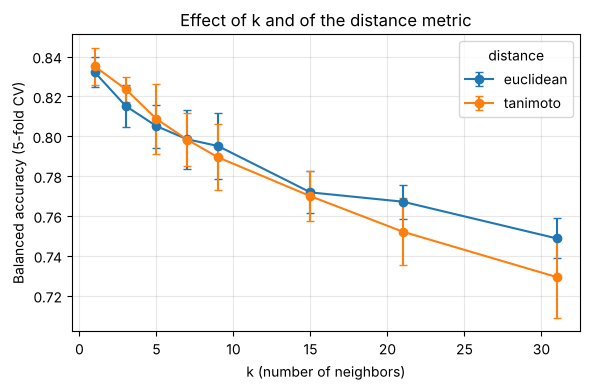

Selected: metric=tanimoto, k=1 (CV balanced accuracy 0.835)


In [10]:
def plot_k_sweep(cv_results):
    """Plot cross-validated balanced accuracy against k, one curve per metric."""
    figure, axes = plt.subplots(figsize=(6, 4))
    for metric, group in cv_results.groupby("metric"):
        axes.errorbar(group["k"], group["balanced_accuracy"], yerr=group["std"],
                      marker="o", capsize=3, label=metric)
    axes.set_xlabel("k (number of neighbors)")
    axes.set_ylabel(f"Balanced accuracy ({CV_FOLDS}-fold CV)")
    axes.set_title("Effect of k and of the distance metric")
    axes.legend(title="distance")
    axes.grid(alpha=0.3)
    figure.tight_layout()
    return axes


plot_k_sweep(cv_results)
plt.show()

best = cv_results.loc[cv_results["balanced_accuracy"].idxmax()]
BEST_METRIC, BEST_K = best["metric"], int(best["k"])
print(f"Selected: metric={BEST_METRIC}, k={BEST_K} "
      f"(CV balanced accuracy {best['balanced_accuracy']:.3f})")

### Evaluation on the test set

The selected configuration is now fitted on the whole training set and measured
once on the held-out molecules. Accuracy alone is misleading with unbalanced
classes, so balanced accuracy, the Matthews correlation coefficient (MCC) and
ROC-AUC are also reported. The k-NN score is the fraction of the `k` neighbors
that are active, which is what ROC-AUC and the ranking use.

In [11]:
def evaluate_knn(model, query_distances, true_labels):
    """Print classification metrics suited to unbalanced data."""
    predicted = model.predict(query_distances)
    scores = model.predict_proba(query_distances)[:, 1]
    print(classification_report(true_labels, predicted, labels=[0, 1],
                                target_names=[NEGATIVE_LABEL, POSITIVE_LABEL], digits=3))
    confusion = pd.DataFrame(confusion_matrix(true_labels, predicted, labels=[0, 1]),
                             index=pd.Index([NEGATIVE_LABEL, POSITIVE_LABEL], name="Actual"),
                             columns=pd.Index([NEGATIVE_LABEL, POSITIVE_LABEL], name="Predicted"))
    print(confusion, "\n")
    print(f"Balanced accuracy: {balanced_accuracy_score(true_labels, predicted):.3f}")
    print(f"MCC:               {matthews_corrcoef(true_labels, predicted):.3f}")
    print(f"ROC-AUC:           {roc_auc_score(true_labels, scores):.3f}")


model = fit_knn(distance_matrix(train_features, train_features, BEST_METRIC),
                train_labels, BEST_K)
evaluate_knn(model, distance_matrix(test_features, train_features, BEST_METRIC), test_labels)

              precision    recall  f1-score   support

    inactive      0.833     0.801     0.816       336
      active      0.865     0.889     0.877       485

    accuracy                          0.853       821
   macro avg      0.849     0.845     0.847       821
weighted avg      0.852     0.853     0.852       821

Predicted  inactive  active
Actual                     
inactive        269      67
active           54     431 

Balanced accuracy: 0.845
MCC:               0.694
ROC-AUC:           0.845


### Ranking new molecules

`rank_molecules` scores any table with a `smiles` column and sorts it by the
fraction of active neighbors (higher = more likely active), which is the
prioritization step in virtual screening. That score can only take `k + 1`
distinct values, so it produces many ties at small `k`; ties are broken by the
distance to the nearest labeled molecule, closest first. That distance is
reported as well, because a large value means the molecule has no close analog
in the training set and its prediction is an extrapolation. Here the held-out
test molecules play the role of new candidates; for a real screen, load your own
CSV.

In [12]:
def rank_molecules(model, molecules, reference_features, metric=None, k=None,
                   smiles_column=SMILES_COLUMN):
    """Score and rank new molecules by the fraction of active neighbors."""
    if smiles_column not in molecules.columns:
        raise ValueError(f"Missing column: {smiles_column}")
    metric = BEST_METRIC if metric is None else metric
    k = model.n_neighbors if k is None else k

    distances = distance_matrix(morgan_bit_vectors(molecules[smiles_column]),
                               reference_features, metric)
    ranked = molecules.copy()
    ranked["active_neighbor_fraction"] = model.predict_proba(distances)[:, 1]
    ranked["predicted_activity"] = np.where(model.predict(distances) == 1,
                                            POSITIVE_LABEL, NEGATIVE_LABEL)
    ranked["nearest_neighbor_distance"] = distances.min(axis=1)
    return ranked.sort_values(["active_neighbor_fraction", "nearest_neighbor_distance"],
                              ascending=[False, True]).reset_index(drop=True)


candidates = dataset.iloc[test_idx].drop(columns=["canonical_smiles"])
ranking = rank_molecules(model, candidates, train_features)
ranking.to_csv(PREDICTIONS_FILE, index=False)
ranking.head(10)

,molecule_chembl_id,smiles,ic50_nm,activity,active_neighbor_fraction,predicted_activity,nearest_neighbor_distance
0,CHEMBL25030,COc1ccc2c(c1)c(CC(=O)N[C@H](CO)C(C)C)c(C)n2C(=...,370.0,active,1.0,active,0.0
1,CHEMBL2096836,Cc1cc(=O)c(Oc2ccc(F)cc2F)c(-c2ccc([S@+](C)[O-]...,270.0,active,1.0,active,0.0
2,CHEMBL100092,CCCCCCOC(=O)Cc1c(C)n(C(=O)c2ccc(Cl)cc2)c2ccc(O...,60.0,active,1.0,active,0.0
3,CHEMBL513405,Cc1ccc(-c2cn[se]c2-c2ccc(Cl)cc2)cc1,0.0,active,1.0,active,0.0
4,CHEMBL1630256,CC(C)CN(C)c1cc2c(cc1Cl)C=C(C(=O)O)[C@@H](C(F)(...,870.0,active,1.0,active,0.0
5,CHEMBL3576978,Cc1ccc(S(=O)(=O)n2cc(C(=O)C(=O)N[C@H](Cc3c[nH]...,1000.0,active,1.0,active,0.0
6,CHEMBL435298,C[C@H](C(=O)O)c1ccc(-c2ccccc2)c(F)c1,910.0,active,1.0,active,0.0
7,CHEMBL25035,CC[C@@H](C)NC(=O)Cc1c(C)n(C(=O)c2ccc(Cl)cc2)c2...,130.0,active,1.0,active,0.0
8,CHEMBL190083,C[C@@H](C(=O)O)c1ccc(-c2ccccc2)c(F)c1,123000.0,inactive,1.0,active,0.0
9,CHEMBL318206,COc1ccc2c(c1)c(CC(=O)N[C@H](C)c1ccc(C)cc1)c(C)...,60.0,active,1.0,active,0.0


## Results, limitations and references

In the worked example (COX-2: 4,105 molecules, 2,427 active and 1,678 inactive,
with 821 held out for testing), cross-validation selected Tanimoto distance with
`k = 1` (balanced accuracy 0.835). On the held-out test set that configuration
reached a balanced accuracy of 0.845, an MCC of 0.694 and a ROC-AUC of 0.845.

Two observations from the sweep:

- Accuracy falls as `k` grows, from 0.835 at `k = 1` to 0.729 at `k = 31`. This
  dataset is made largely of series of close analogs, so the single nearest
  molecule is already the best available evidence, and enlarging the
  neighborhood only mixes in less relevant compounds and favors the majority
  class.
- Tanimoto is ahead for small neighborhoods (0.835 vs 0.832 at `k = 1`, 0.824 vs
  0.815 at `k = 3`), the two metrics tie at `k = 7`, and Euclidean distance is
  slightly ahead from `k = 9` on (0.749 vs 0.729 at `k = 31`). The choice of
  metric therefore interacts with `k` rather than being good or bad on its own.

Compared with the support vector machine trained on the same molecules and the
same fingerprints, k-NN reaches a similar balanced accuracy and MCC but a clearly
lower ROC-AUC (0.845 against 0.92). The reason is the score itself: with `k = 1`
the fraction of active neighbors is either 0 or 1, so molecules cannot be finely
ranked and ROC-AUC collapses onto the accuracy. Larger `k` gives a smoother score
at the cost of accuracy, which is a real trade-off when the purpose is to rank a
library rather than to classify.

Limitations:

- Performance depends strongly on `k` and on the distance metric, as the sweep
  above shows; both must be re-selected for every new dataset.
- There is no compression of the training data: every prediction compares the
  query against all stored molecules, so cost grows with the size of the
  reference set. Screening very large libraries requires approximate neighbor
  search or prior filtering.
- Morgan fingerprints ignore features such as stereochemistry and can map
  distinct molecules onto the same bit-vector. In the example, 46 of the 821 test
  molecules have a training molecule at Tanimoto distance 0, and 10 of those are
  still misclassified: identical fingerprints carrying opposite labels. No
  fingerprint-based method can separate such pairs, and `k = 1` simply copies the
  label of whichever one it finds.
- Labels depend on the chosen thresholds and mix IC50 values from different
  assays and laboratories.
- Predictions are only reliable for molecules that have close neighbors in the
  training set, and require experimental confirmation.

References:

1. Oliveira, T.A.; Silva, M.P.; Maia, E.H.B.; Silva, A.M.; Taranto, A.G. Virtual
   Screening Algorithms in Drug Discovery: A Review Focused on Machine and Deep
   Learning Methods. *Drugs Drug Candidates* **2023**, 2, 311-334.
   https://doi.org/10.3390/ddc2020017
2. Shen, M. et al. Application of predictive QSAR models to database mining:
   identification and experimental validation of novel anticonvulsant compounds.
   *J. Med. Chem.* **2004**, 47, 2356-2364. https://doi.org/10.1021/jm030584q
3. Peterson, Y.K. et al. Discovery of geranylgeranyltransferase-I inhibitors with
   novel scaffolds by the means of quantitative structure-activity relationship
   modeling, virtual screening, and experimental validation. *J. Med. Chem.*
   **2009**, 52, 4210-4220. https://doi.org/10.1021/jm8013772
4. Rogers, D.; Hahn, M. Extended-connectivity fingerprints. *J. Chem. Inf. Model.*
   **2010**, 50, 742-754. https://doi.org/10.1021/ci100050t
5. Bajusz, D.; Racz, A.; Heberger, K. Why is Tanimoto index an appropriate choice
   for fingerprint-based similarity calculations? *J. Cheminform.* **2015**, 7, 20.
   https://doi.org/10.1186/s13321-015-0069-3
6. Zdrazil, B. et al. The ChEMBL Database in 2023: a drug discovery platform
   spanning multiple bioactivity data types and time periods. *Nucleic Acids Res.*
   **2024**, 52, D1180-D1192. https://doi.org/10.1093/nar/gkad1004
7. Pedregosa, F. et al. Scikit-learn: Machine Learning in Python. *J. Mach. Learn.
   Res.* **2011**, 12, 2825-2830.
8. RDKit: Open-source cheminformatics. https://www.rdkit.org